# Black-ink scan → LAS by line style (pyLogDigitizer 0.3.0)

A black-and-white log prints several curves in one track and tells them apart by **line style**: solid, dashed, dotted or dash-dot, thin or thick. This notebook runs the same flow as the colour notebook (`04_color_scan_to_las.ipynb`), with line styles in place of ink colours:

1. **Suggest**: find the tracks, then label the curve ink in each track by line style.
2. **Confirm**: name each style, give its scale (from the OCR'd header where it is printed).
3. **One working image per curve**: only that style's ink, gaps closed, on top of the grid and depth numbers.
4. **Trace** each working image on its own scale with an assisted session (dense points, no smoothing).
5. **LAS** on a 0.5 ft grid, and a check against the public KGS LAS.

The example is the shipped crop of the USA 'A' 16 log (Kansas Geological Survey, 1-bit scan). Provenance, credit line and terms are in `example_data/SOURCES.txt`: *The source of this material is the Kansas Geological Survey website at http://www.kgs.ku.edu/. All Rights Reserved.*

This is a proof of concept: the style classes are proposals to confirm. On this print the dashed neutron curve runs beside, and often touches, the solid density curve, with stippled shading between them; it is the weak case (see the check and the notes at the end).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from pylogdigitizer import line_styles as ls
from pylogdigitizer.curve_ink import save_ink_tif
from pylogdigitizer.header_ocr import propose_header
from pylogdigitizer.workflows import analyze_layout, calibrate_depth, open_color_curve, color_curve_values
from pylogdigitizer.las_export import read_las, resample, common_grid, write_las
from pylogdigitizer import qc_compare as qc

ROOT = Path(".").resolve()
if not (ROOT / "example_data").exists():
    ROOT = ROOT.parent
WELL = ROOT / "example_data/USA_A_16_15-055-20536"
SCAN = WELL / "4342_crop_3260-4770.tif"
LAS = WELL / "USA_A_16_4342_crop_3200-4800.las"
FIG = ROOT / "image" / "ex_linestyle_usa.png"
WORK = ROOT / "outputs" / "line_styles_usa"
WORK.mkdir(parents=True, exist_ok=True)
print("scan:", SCAN.relative_to(ROOT), SCAN.exists(), "| LAS:", LAS.relative_to(ROOT), LAS.exists())

scan: example_data/USA_A_16_15-055-20536/4342_crop_3260-4770.tif True | LAS: example_data/USA_A_16_15-055-20536/USA_A_16_4342_crop_3200-4800.las True


## 1. Layout, depth and header

`analyze_layout` finds the tracks and the depth numbers; nothing about positions is passed in. The header band (top 440 rows of the crop) is read by the default header parser.

In [2]:
L = analyze_layout(SCAN)
dm, anc, residuals, dchecks = calibrate_depth(L, track="track1", use_ocr=True)
print("layout:", L.layout_mode, "| tracks:", L.track_names)
print({k: dchecks[k] for k in ("px_per_ft", "first_depth", "interval", "n_labels", "source")})

def track_x(name):
    li, ri = L.edge_names.index(name + ".left"), L.edge_names.index(name + ".right")
    return float(np.median(L.edges[:, li])), float(np.median(L.edges[:, ri]))

tracks = {n: track_x(n) for n in L.track_names}
HEADER_H = 440
BODY = (HEADER_H, L.ink.shape[0])
print("track x (px):", {k: tuple(round(v) for v in xy) for k, xy in tracks.items()})

H = propose_header(str(SCAN), layout=L)
for c in H["curves"]:
    b = c["backup"]["value"]
    print(f"  {c['track']:8s} {c['mnemonic']['value']:6s} {c['scale_left']['value']} .. {c['scale_right']['value']}"
          f"  {c['scale_type']['value']}  backup={b}")

layout: default | tracks: ['track1', 'track2']
{'px_per_ft': 15.12, 'first_depth': 3300.0, 'interval': 100.0, 'n_labels': 16, 'source': 'ocr'}
track x (px): {'track1': (72, 826), 'track2': (1052, 2531)}


  track1   GR     0.0 .. 150.0  linear  backup=[150.0, 300.0]
  track1   CALI   6.0 .. 16.0  linear  backup=None


## 2. Suggest line styles

`line_styles.suggest_line_styles` removes the grid, then splits each track's curve ink into pieces and classifies them:

- **pattern**: long pieces are solid; short pieces are dashes or dots by length; a dash with one or two dots next to it is dash-dot. Dense stipple (shading) and lone specks are ignored.
- **weight**: an opening splits heavy from light ink; a style is *thick* when its stroke is clearly wider than the thinnest one in the track. When every style in a track has the same weight, no weight word is added.

Styles covering less than 25 % of the track's depth are dropped. The result follows the colour convention: a label image with one class per style, so the colour workflow (working images, tracing, LAS) is reused unchanged.

In [3]:
S = ls.suggest_line_styles(L.ink, tracks, BODY)
for t, styles in S["styles"].items():
    print(t, [(s["name"], round(s["coverage"], 2)) for s in styles])

track1 [('solid thick', 0.97), ('dotted thin', 0.56)]
track2 [('solid thick', 0.99), ('dotted thin', 0.88), ('dashed thick', 0.6)]


## 3. Confirm: name, scale and unit per style

On this print track 1 carries gamma ray (solid, thick; header 0–150 API with a 150–300 backup and hatched fill where it goes off scale) and caliper (dotted, thin; header 6–16 in).

Tracks 2–3 are one porosity track whose header boxes are blank on this print. It carries four curves: density porosity (solid, thick), neutron porosity (dashed, thick, running beside the density curve with stippled crossover shading between them), and two curves the LAS does not have (a second thick dashed curve near the right side and a thin dotted one). Those two are not traced here: the *dotted thin* class in this track also holds the stippled shading, so a trace of it would not be reliable. The scale is the usual porosity scale for this kind of log, **30 to −10 porosity units (limestone matrix)** across the track. It is not printed, so it is an assumption, checked against the LAS below: a straight-line fit of the traced solid curve against the LAS density converted to limestone density porosity, (2.71 − RHOB) / 1.71, gives 30.2 to −9.9.

The neutron dashes touch the density curve and the shading, so step 2 puts most of them in the *solid thick* class. They are split off after the density curve is traced (`line_styles.reassign_off_trace`, step 5). The two thick dashed curves have the same style and never cross, so both are traced together and the left one is kept (`pick="left"`).

In [4]:
hdr = {c["mnemonic"]["value"]: c for c in H["curves"]}
gr, cali = hdr["GR"], hdr["CALI"]
PORO = dict(left=30.0, right=-10.0, unit="PU", backup=None)   # assumed: header boxes are blank (see above)
CURVES = [
    dict(name="GR", style="solid thick", track="track1", left=gr["scale_left"]["value"], right=gr["scale_right"]["value"],
         backup=tuple(gr["backup"]["value"]), use_hatch=True, unit="GAPI", ref="GR"),
    dict(name="CALI", style="dotted thin", track="track1", left=cali["scale_left"]["value"], right=cali["scale_right"]["value"],
         backup=None, unit="IN", ref=None),
    dict(PORO, name="DPHI", style="solid thick", track="track2", ref="DPHI_LS"),
    dict(PORO, name="NPHI", style="dashed thick", track="track2", ref="NPHI",
         split_from="DPHI", trace=dict(n_curves=2, pick="left")),
]
for cv in CURVES:
    print(f"{cv['name']:10s} {cv['style']:13s} {cv['track']}  {cv['left']:g}..{cv['right']:g} {cv['unit']}  backup={cv['backup']}")

GR         solid thick   track1  0..150 GAPI  backup=(150.0, 300.0)
CALI       dotted thin   track1  6..16 IN  backup=None
DPHI       solid thick   track2  30..-10 PU  backup=None
NPHI       dashed thick  track2  30..-10 PU  backup=None


## 4. One working image per curve

`make_style_base` keeps the grid, borders, depth numbers and header and removes all curve ink. `make_style_ink` adds back only the chosen style inside its track, closes the gaps of that pattern (dashes and dots join into one line) and thickens the stroke, so the tracer sees one continuous curve. The neutron image is built in step 5, after the density curve is traced.

In [5]:
base = ls.make_style_base(L.ink, S)
ink_paths = {}

def working_image(cv, sug):
    ink = ls.make_style_ink(base, sug, cv["style"], tracks[cv["track"]], BODY)
    return save_ink_tif(ink, WORK / f"working_{cv['name']}.tif")

for cv in CURVES:
    if "split_from" not in cv:
        ink_paths[cv["name"]] = working_image(cv, S)
        print(cv["name"], "->", ink_paths[cv["name"]].relative_to(ROOT))
print("black-ink tracer preset:", ls.LINE_TRACE_PRESET)

GR -> outputs/line_styles_usa/working_GR.tif


CALI -> outputs/line_styles_usa/working_CALI.tif


DPHI -> outputs/line_styles_usa/working_DPHI.tif
black-ink tracer preset: {'min_area': 0}


## 5. Trace each curve on its own scale

Each working image is opened as an assisted session (`open_color_curve`), which re-finds the layout and depth on the 1-bit image and auto-traces the curve. Off-scale: a wrapped trace or a hatched fill is read on the backup scale; a curve clipped at the edge with no wrapped trace is written as null.

For the neutron curve, `reassign_off_trace` first gives the *dashed thick* class the ink that touches the traced density curve but lies outside a 7 px corridor around it (the neutron dashes, not the shading). Where the two curves overlap within that corridor the neutron dashes merge into the solid stroke and the neutron class has no ink there. `route_hidden_along_trace` finds those stretches (no *dashed thick* ink within 60 px of the density trace for at least 15 rows). There the neutron line is routed along the density trace only so it stays connected instead of wandering to the next dashed ink in the track; it is not a neutron reading. `set_hidden_interval` marks the stretches on the session, so their depths are null in the values and the LAS (the same rule as a curve clipped off the track), the figure draws them as a faint dotted connector, and the app's *Trace and fix* tab lists each one as a tricky spot. Short stretches with a few stray dashes nearby are not caught, and the trace can still jump to the second dashed curve there (e.g. near 3900–3906 ft).

In [6]:
sessions, series, sugs = {}, {}, {"S": S}

def trace(cv):
    s = open_color_curve(ink_paths[cv["name"]], dict(cv, color=cv["style"], scale_type="linear"), "USA_A_16",
                         dict(ls.LINE_TRACE_PRESET, **cv.get("trace", {})), x_range=tracks[cv["track"]], auto_backup=False)
    for a, b in cv.get("hidden", []):     # ink hidden under another curve: the line runs along it, values are null
        s.set_hidden_interval(a, b)
    sessions[cv["name"]] = s
    d, v = color_curve_values(s)
    series[cv["name"]] = (d, v)
    print(f"{cv['name']:10s} n={len(d)} finite={int(np.isfinite(v).sum())} "
          f"{float(np.nanmin(d)):.0f}-{float(np.nanmax(d)):.0f} ft  errors={s.errors}")

for cv in CURVES:
    if "split_from" in cv:
        R = sessions[cv["split_from"]].result()
        rows = np.asarray(R["rows"], float)
        xs = np.asarray(sessions[cv["split_from"]].panel_to_sheet(rows, np.asarray(R["x_panel"], float)), float)
        src = next(c for c in CURVES if c["name"] == cv["split_from"])
        S2 = ls.reassign_off_trace(S, src["style"], cv["style"], tracks[cv["track"]], rows, xs, BODY)
        sugs[cv["name"]] = S2
        ink = ls.make_style_ink(base, S2, cv["style"], tracks[cv["track"]], BODY)
        # where the dashes run under the solid stroke for feet at a time, the line is routed along the
        # solid trace to stay connected, and those depths are null (session.set_hidden_interval)
        ink, hidden, cv["hidden"] = ls.route_hidden_along_trace(ink, S2, cv["style"], rows, xs)
        ink_paths[cv["name"]] = save_ink_tif(ink, WORK / f"working_{cv['name']}.tif")
        print(cv["name"], "->", ink_paths[cv["name"]].relative_to(ROOT), f"(split off the {cv['split_from']} trace; {len(cv['hidden'])} stretches, {hidden.mean():.0%} of it, hidden under that trace -> null)")
    trace(cv)

GR         n=8080 finite=8043 3255-4858 ft  errors={}


CALI       n=8080 finite=4651 3255-4858 ft  errors={}


DPHI       n=8146 finite=7899 3241-4858 ft  errors={}


NPHI -> outputs/line_styles_usa/working_NPHI.tif (split off the DPHI trace; 47 stretches, 14% of it, hidden under that trace -> null)


NPHI       n=8146 finite=6904 3241-4858 ft  errors={}


## 6. Check against the KGS LAS, on the printed scale

Each traced curve is compared with its own LAS curve in the same units (`qc_compare.compare`: Pearson's *r*, RMSE and bias after the best bulk depth shift within a few feet). Density porosity is compared with the LAS bulk density converted to limestone density porosity, DPHI_LS = (2.71 − RHOB) / 1.71 × 100. A trace cannot read past the track edge, so the second set of numbers keeps only depths where the LAS value is inside the printed scale (GR: 0–150 API, or the 150–300 backup where the trace wraps; porosity: −10 to 30 PU), with the median absolute error and the share of depths within 2 units (2 API for GR is not meaningful, so GR shows within 5 API). The LAS itself was digitized from the paper log, so it is a reference, not ground truth. Caliper has no matching curve in the LAS.

In [7]:
ref = read_las(LAS).df().sort_index()
ref["DPHI_LS"] = (2.71 - ref["RHOB"]) / 1.71 * 100.0
print("LAS curves:", [c for c in ref.columns if c != "DPHI_LS"], "+ DPHI_LS from RHOB")
QC = {}
print(f"{'curve':6s} {'style':13s} {'vs LAS':8s} {'r':>6s} {'RMSE':>6s} {'n':>5s} | in scale: {'r':>6s} {'RMSE':>6s} {'bias':>6s} {'med|e|':>6s} {'within':>7s} {'n':>5s}")
for cv in CURVES:
    if cv["ref"] is None:
        print(f"{cv['name']:6s} {cv['style']:13s} {'-':8s} no reference curve")
        continue
    r = ref[cv["ref"]].dropna()
    C = qc.compare(r.index.values, r.values, *series[cv["name"]])
    a = C["aligned"]
    lo, hi = sorted((cv["left"], cv["right"]))
    if cv.get("backup"):
        lo, hi = min(lo, *cv["backup"]), max(hi, *cv["backup"])
    ref_g, test_g = C["ref"], C["test_aligned"]
    ins = (ref_g >= lo) & (ref_g <= hi)
    m = qc.metrics(np.where(ins, ref_g, np.nan), test_g)
    e = np.abs(test_g - ref_g)[ins & np.isfinite(test_g)]
    tol = 5.0 if cv["unit"] == "GAPI" else 2.0
    m.update(med=float(np.median(e)), within=float(np.mean(e <= tol)), tol=tol)
    QC[cv["name"]] = dict(all=a, in_scale=m)
    print(f"{cv['name']:6s} {cv['style']:13s} {cv['ref']:8s} {a['r']:6.3f} {a['rmse']:6.2f} {a['n']:5d} |"
          f"           {m['r']:6.3f} {m['rmse']:6.2f} {m['bias']:6.2f} {m['med']:6.2f} {m['within']:6.0%}{'':1s} {m['n']:5d}"
          f"  (within {tol:g} {cv['unit']})")


LAS curves: ['GR', 'NPHI', 'RHOB', 'ILD'] + DPHI_LS from RHOB
curve  style         vs LAS        r   RMSE     n | in scale:      r   RMSE   bias med|e|  within     n


GR     solid thick   GR        0.900  11.23  3077 |            0.900  11.23  -0.22   2.03    70%   3077  (within 5 GAPI)
CALI   dotted thin   -        no reference curve
DPHI   solid thick   DPHI_LS   0.814   4.71  2889 |            0.907   2.63  -0.45   0.53    83%   2787  (within 2 PU)
NPHI   dashed thick  NPHI      0.746   4.96  2649 |            0.746   4.96  -0.29   1.19    64%   2649  (within 2 PU)


## 7. Figure (`image/ex_linestyle_usa.png`)

One compact figure over a 60 ft window of tracks 1 and 2: the raw scan, the curve ink coloured by the suggested style, and the per-curve traces drawn back in their line style.

wrote image/ex_linestyle_usa.png 115665 bytes


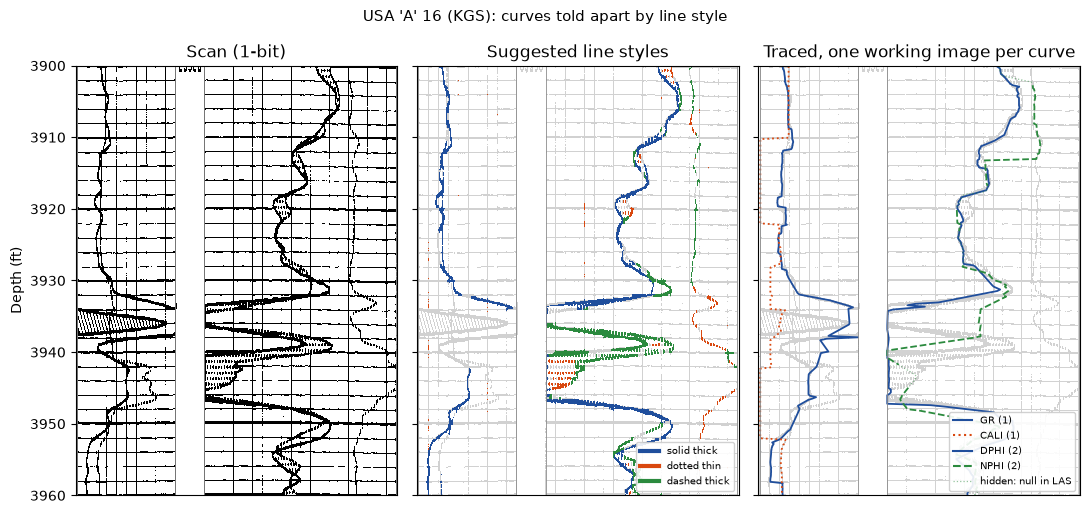

In [8]:
STYLE_COLOR = {"solid thick": "#1f4e9c", "dotted thin": "#d9480f", "dashed thick": "#2b8a3e"}
STYLE_LS = {"solid thick": "-", "dotted thin": ":", "dashed thick": "--"}
WINDOW = (3900, 3960)
rows_all = np.arange(L.ink.shape[0])
dep_all = dm(rows_all)
r0, r1 = (int(np.searchsorted(dep_all, d)) for d in WINDOW)
x0, x1 = int(tracks["track1"][0]) - 10, int(tracks["track2"][1]) + 10
ext = (x0, x1, WINDOW[1], WINDOW[0])

fig, axs = plt.subplots(1, 3, figsize=(11, 5.2), sharey=True)
axs[0].imshow(~L.ink[r0:r1, x0:x1], cmap="gray", extent=ext, aspect="auto", interpolation="nearest")
axs[0].set_title("Scan (1-bit)")
rgbimg = np.ones((r1 - r0, x1 - x0, 3))
lab = sugs["NPHI"]["labels"][r0:r1, x0:x1]
rgbimg[lab == 1] = 0.82
for name, col in STYLE_COLOR.items():
    if name in S["names"]:
        rgbimg[lab == S["names"].index(name)] = plt.matplotlib.colors.to_rgb(col)
axs[1].imshow(rgbimg, extent=ext, aspect="auto", interpolation="nearest")
axs[1].set_title("Suggested line styles")
axs[1].legend(handles=[plt.Line2D([], [], color=c, lw=3, label=n) for n, c in STYLE_COLOR.items()],
              loc="lower right", fontsize=7, framealpha=0.9)
axs[2].imshow(~L.ink[r0:r1, x0:x1], cmap="gray", extent=ext, aspect="auto", interpolation="nearest", alpha=0.18)
for cv in CURVES:
    s = sessions[cv["name"]]
    R = s.result()
    rows = np.asarray(R["rows"], float)
    xs = np.asarray(s.panel_to_sheet(rows, np.asarray(R["x_panel"], float)), float)
    dd = np.asarray(R["depth"], float)
    m = (dd >= WINDOW[0]) & (dd <= WINDOW[1])
    hid = np.zeros(len(rows), bool)
    for a, b in s.hidden_intervals:
        hid |= (rows >= a) & (rows <= b)
    axs[2].plot(np.where(hid, np.nan, xs)[m], dd[m], STYLE_LS[cv["style"]], color=STYLE_COLOR[cv["style"]], lw=1.3)
    if hid[m].any():   # hidden under another curve: a faint dotted connector, null in the LAS
        axs[2].plot(np.where(hid, xs, np.nan)[m], dd[m], ":", color=STYLE_COLOR[cv["style"]], lw=0.9, alpha=0.5)
axs[2].legend(handles=[plt.Line2D([], [], color=STYLE_COLOR[cv["style"]], ls=STYLE_LS[cv["style"]], lw=1.5,
                                  label=f"{cv['name']} ({cv['track'][-1]})") for cv in CURVES]
             + [plt.Line2D([], [], color=STYLE_COLOR["dashed thick"], ls=":", lw=0.9, alpha=0.5, label="hidden: null in LAS")],
              loc="lower right", fontsize=7, framealpha=0.9)
axs[2].set_title("Traced, one working image per curve")
for ax in axs:
    ax.set_xticks([]); ax.set_xlim(x0, x1); ax.set_ylim(WINDOW[1], WINDOW[0])
    for t in tracks.values():
        for x in t:
            ax.axvline(x, color="0.55", lw=0.6)
axs[0].set_ylabel("Depth (ft)")
fig.suptitle("USA 'A' 16 (KGS): curves told apart by line style", fontsize=11)
fig.tight_layout()
FIG.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG, dpi=110, bbox_inches="tight")
print("wrote", FIG.relative_to(ROOT), FIG.stat().st_size, "bytes")
plt.show()

## 7b. Check figure (`image/ex_qc_usa.png`)

Each traced curve against its KGS LAS curve over the whole log, after the same bulk depth shift as above, with the in-scale numbers in the title. Telling curves apart by line style on a 1-bit scan works, but it is less exact than reading ink colours: where dashes, dots and the solid stroke cross, a trace can follow the wrong stroke for a few feet, and depths hidden under another curve are left null.

wrote image/ex_qc_usa.png 162948 bytes


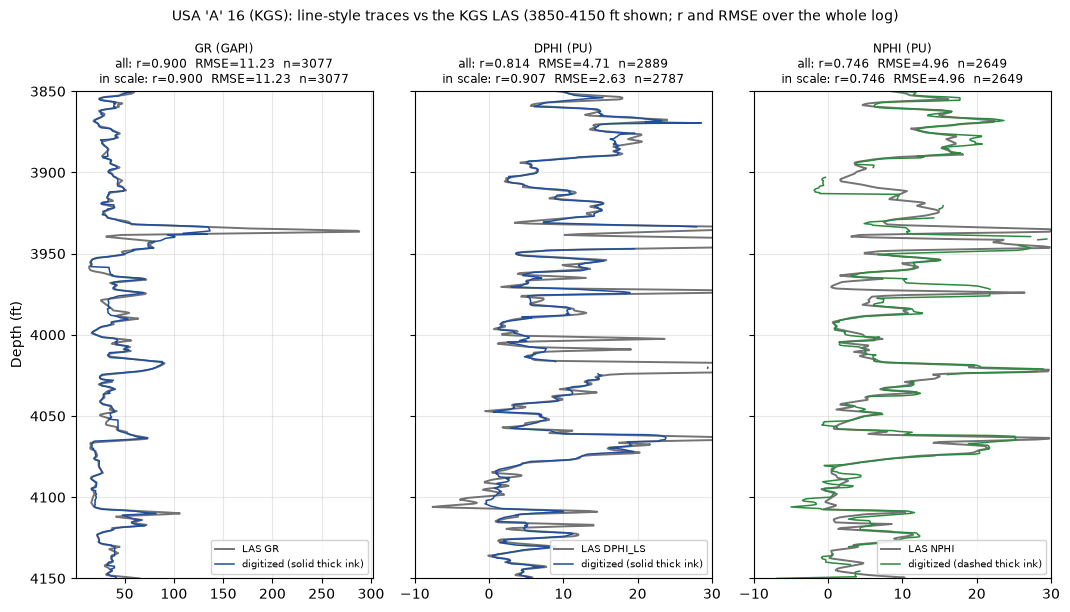

In [9]:
FIG_QC = ROOT / "image" / "ex_qc_usa.png"
WIN_QC = (3850, 4150)      # depths drawn (the numbers are over the whole log)
show = [cv for cv in CURVES if cv["ref"] is not None]
fig, axs = plt.subplots(1, len(show), figsize=(3.6 * len(show), 6.2), sharey=True)
for ax, cv in zip(np.atleast_1d(axs), show):
    r = ref[cv["ref"]].dropna()
    C = qc.compare(r.index.values, r.values, *series[cv["name"]])
    a, m = QC[cv["name"]]["all"], QC[cv["name"]]["in_scale"]
    w = (C["grid"] >= WIN_QC[0]) & (C["grid"] <= WIN_QC[1])
    ax.plot(C["ref"][w], C["grid"][w], color="0.45", lw=1.4, label=f"LAS {cv['ref']}")
    ax.plot(C["test_aligned"][w], C["grid"][w], color=STYLE_COLOR[cv["style"]], lw=1.1, label=f"digitized ({cv['style']} ink)")
    lo, hi = sorted((cv["left"], cv["right"]))
    ax.set_xlim(lo, hi) if not cv.get("backup") else None
    ax.set_title(f"{cv['name']} ({cv['unit']})\nall: r={a['r']:.3f}  RMSE={a['rmse']:.2f}  n={a['n']}\n"
                 f"in scale: r={m['r']:.3f}  RMSE={m['rmse']:.2f}  n={m['n']}", fontsize=8.5)
    ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=7, framealpha=0.9)
np.atleast_1d(axs)[0].set_ylabel("Depth (ft)"); np.atleast_1d(axs)[0].set_ylim(WIN_QC[1], WIN_QC[0])
fig.suptitle(f"USA 'A' 16 (KGS): line-style traces vs the KGS LAS ({WIN_QC[0]}-{WIN_QC[1]} ft shown; r and RMSE over the whole log)", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_QC, dpi=110, bbox_inches="tight")
print("wrote", FIG_QC.relative_to(ROOT), FIG_QC.stat().st_size, "bytes")
plt.show()


## 8. Write LAS (0.5 ft grid, no smoothing)

In [10]:
grid, curves = common_grid(series, step=0.5)
units = {cv["name"]: cv["unit"] for cv in CURVES}
out = WORK / "USA_A_16_line_styles.las"
write_las(out, grid, curves, units=units, well={"WELL": "USA 'A' 16", "UWI": "15-055-20536"})
print("wrote", out.relative_to(ROOT), "n=", len(grid), "from", float(grid[0]), "to", float(grid[-1]))
for k, v in curves.items():
    print(f"  {k:10s} finite {int(np.isfinite(v).sum())}/{len(v)}")

wrote outputs/line_styles_usa/USA_A_16_line_styles.las n= 3234 from 3241.5 to 4858.0
  GR         finite 3192/3234
  CALI       finite 1838/3234
  DPHI       finite 3130/3234
  NPHI       finite 2731/3234


## Notes and limits

- Line styles are proposals: confirm or rename them, as with the colour palette. `header_ocr.legend_styles` reads printed legend strokes where a header has them, and `line_styles.match_legend` pairs them with the suggested styles.
- Gamma ray reads as well from its style-isolated working image as from the whole scan (`01_conventional_vs_assisted.ipynb`).
- The neutron curve (thick dashed) is the weak case on this print. It runs within a few pixels of the density curve over long stretches, touches it and the stippled shading, and a second thick dashed curve shares its style near the right of the track. Splitting the shared ink along the density trace and keeping the left of two dashed candidates recovers most of it, and where the dashes are hidden under the solid stroke the depths are written as null (the line only runs along the density trace to stay connected). It still cannot tell the two porosity curves apart where they overlap, and over short stretches it can jump to the other dashed curve. Check the trace against the scan, and fix such stretches with the anchors in the assisted session (the app's *Trace and fix* tab).
- The porosity scale of tracks 2–3 is not printed on this header; it is confirmed from the density curve (see step 3), not read.
- In the local app the same flow runs from the *Curves* tab: curves are identified by colour, by line style, or both.